In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

print("Entorno configurado correctamente")

Entorno configurado correctamente


In [ ]:
# Frecuencia de muestreo
fs = 50000

# Frecuencia de la portadora
fc = 10000

# Tasa de símbolos
Rs = 1000

# Muestras por símbolo
muestras_simbolo = int(fs / Rs)

# Número de símbolos por señal
num_simbolos = 64

# Niveles de ruido
niveles_snr = [0, 5, 10, 15, 20]

print("Frecuencia de muestreo:", fs)
print("Frecuencia portadora:", fc)
print("Tasa de símbolos:", Rs)
print("Muestras por símbolo:", muestras_simbolo)

Frecuencia de muestreo: 50000
Frecuencia portadora: 10000
Tasa de símbolos: 1000
Muestras por símbolo: 50


In [ ]:
def generar_ASK():
    bits = np.random.randint(0, 2, num_simbolos)

    amplitudes = np.where(bits == 0, 0.3, 1.0)

    t = np.arange(num_simbolos * muestras_simbolo) / fs

    amplitud = np.repeat(amplitudes, muestras_simbolo)

    señal = amplitud * np.cos(2 * np.pi * fc * t)

    return señal

In [ ]:
def generar_FSK():
    bits = np.random.randint(0, 2, num_simbolos)

    frecuencias = np.where(bits == 0, 8000, 12000)

    señal = []

    for f in frecuencias:
        t = np.arange(muestras_simbolo) / fs
        segmento = np.cos(2 * np.pi * f * t)
        señal.extend(segmento)

    return np.array(señal)

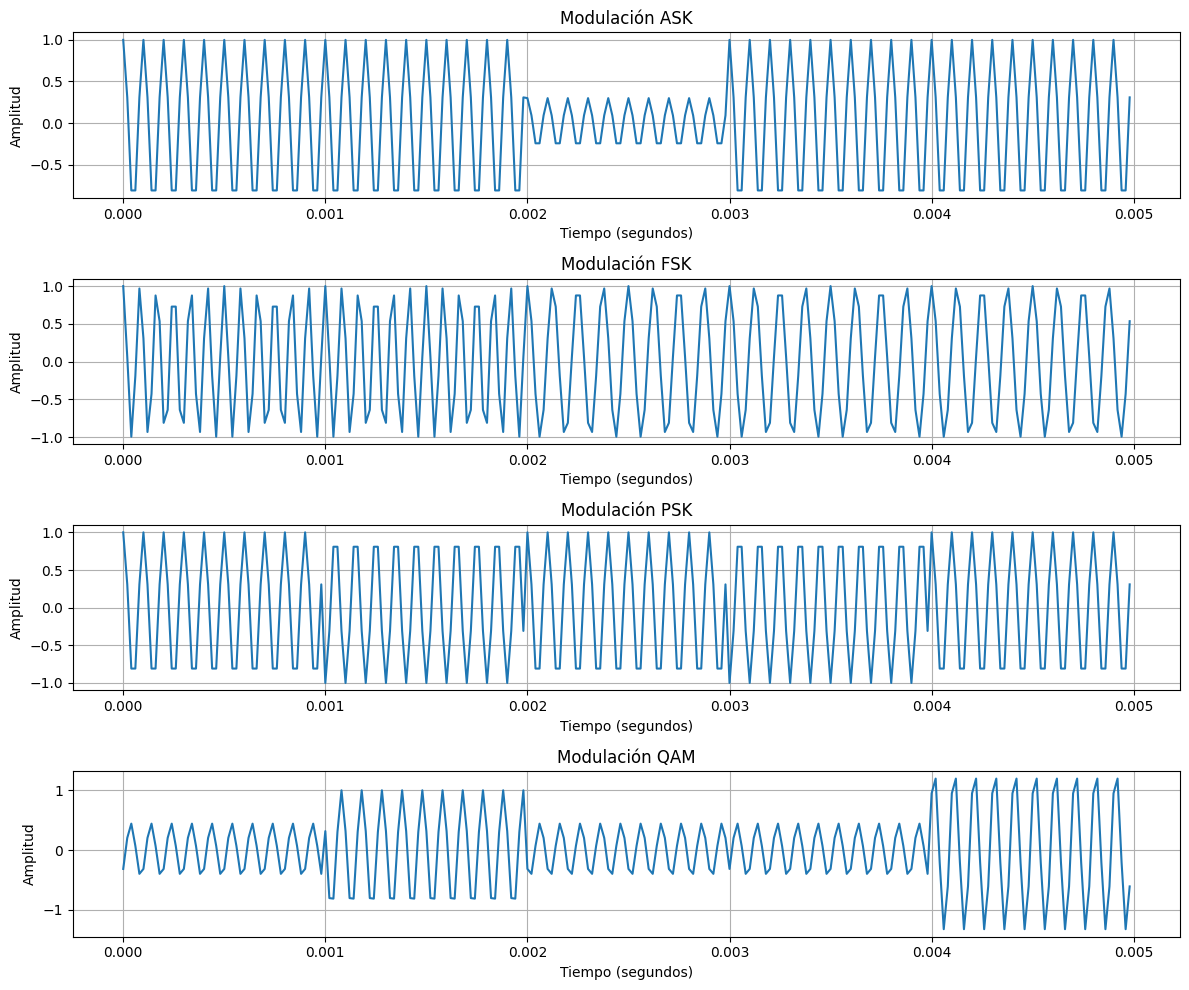

In [ ]:

fig, ejes = plt.subplots(4, 1, figsize=(12, 10))

for i, (nombre, funcion) in enumerate(generadores.items()):

    señal = funcion()

    tiempo = np.arange(len(señal)) / fs

    # Mostrar solamente los primeros 5 símbolos
    muestras_grafica = 5 * muestras_simbolo

    ejes[i].plot(
        tiempo[:muestras_grafica],
        señal[:muestras_grafica]
    )

    ejes[i].set_title("Modulación " + nombre)
    ejes[i].set_xlabel("Tiempo (segundos)")
    ejes[i].set_ylabel("Amplitud")
    ejes[i].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
def generar_QAM():
    bits = np.random.randint(0, 2, (num_simbolos, 4))

    niveles = np.array([-3, -1, 1, 3])

    indice_I = bits[:, 0] * 2 + bits[:, 1]
    indice_Q = bits[:, 2] * 2 + bits[:, 3]

    I = niveles[indice_I]
    Q = niveles[indice_Q]

    I = I / np.sqrt(10)
    Q = Q / np.sqrt(10)

    I = np.repeat(I, muestras_simbolo)
    Q = np.repeat(Q, muestras_simbolo)

    t = np.arange(num_simbolos * muestras_simbolo) / fs

    señal = I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)

    return señal

In [ ]:
def generar_QAM():
    bits = np.random.randint(0, 2, (num_simbolos, 4))

    niveles = np.array([-3, -1, 1, 3])

    indice_I = bits[:, 0] * 2 + bits[:, 1]
    indice_Q = bits[:, 2] * 2 + bits[:, 3]

    I = niveles[indice_I]
    Q = niveles[indice_Q]

    I = I / np.sqrt(10)
    Q = Q / np.sqrt(10)

    I = np.repeat(I, muestras_simbolo)
    Q = np.repeat(Q, muestras_simbolo)

    t = np.arange(num_simbolos * muestras_simbolo) / fs

    señal = I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)

    return señal

In [ ]:
generadores = {
    "ASK": generar_ASK,
    "FSK": generar_FSK,
    "PSK": generar_PSK,
    "QAM": generar_QAM
}

datos = []
etiquetas = []
snr_guardados = []

for nombre, funcion in generadores.items():

    for i in range(1000):

        señal = funcion()

        # Normalizar potencia
        señal = señal / np.sqrt(np.mean(señal**2))

        datos.append(señal)
        etiquetas.append(nombre)

        snr_guardados.append(-1)

X = np.array(datos, dtype=np.float32)
y = np.array(etiquetas)

print("Dataset generado correctamente")
print("Total de señales:", len(X))
print("Forma del dataset:", X.shape)

print(pd.Series(y).value_counts())

Dataset generado correctamente
Total de señales: 4000
Forma del dataset: (4000, 3200)
ASK    1000
FSK    1000
PSK    1000
QAM    1000
Name: count, dtype: int64


In [ ]:
def agregar_ruido_AWGN(señal, snr_db):

    potencia = np.mean(señal**2)

    snr_lineal = 10 ** (snr_db / 10)

    potencia_ruido = potencia / snr_lineal

    ruido = np.random.normal(
        0,
        np.sqrt(potencia_ruido),
        len(señal)
    )

    return señal + ruido

In [ ]:
X_limpio = X.copy()

X_ruidoso = []
snr_final = []

for señal in X_limpio:

    snr = np.random.choice(niveles_snr)

    señal_ruidosa = agregar_ruido_AWGN(señal, snr)

    X_ruidoso.append(señal_ruidosa)
    snr_final.append(snr)

X_ruidoso = np.array(X_ruidoso, dtype=np.float32)

snr_final = np.array(snr_final)

print("Ruido AWGN agregado correctamente")
print("Señales con ruido:", len(X_ruidoso))

Ruido AWGN agregado correctamente
Señales con ruido: 4000


In [ ]:
X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X_ruidoso,
    y,
    snr_final,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATOS DE ENTRENAMIENTO:", len(X_train))
print("DATOS DE PRUEBA:", len(X_test))

print("Separación realizada correctamente")

DATOS DE ENTRENAMIENTO: 3200
DATOS DE PRUEBA: 800
Separación realizada correctamente


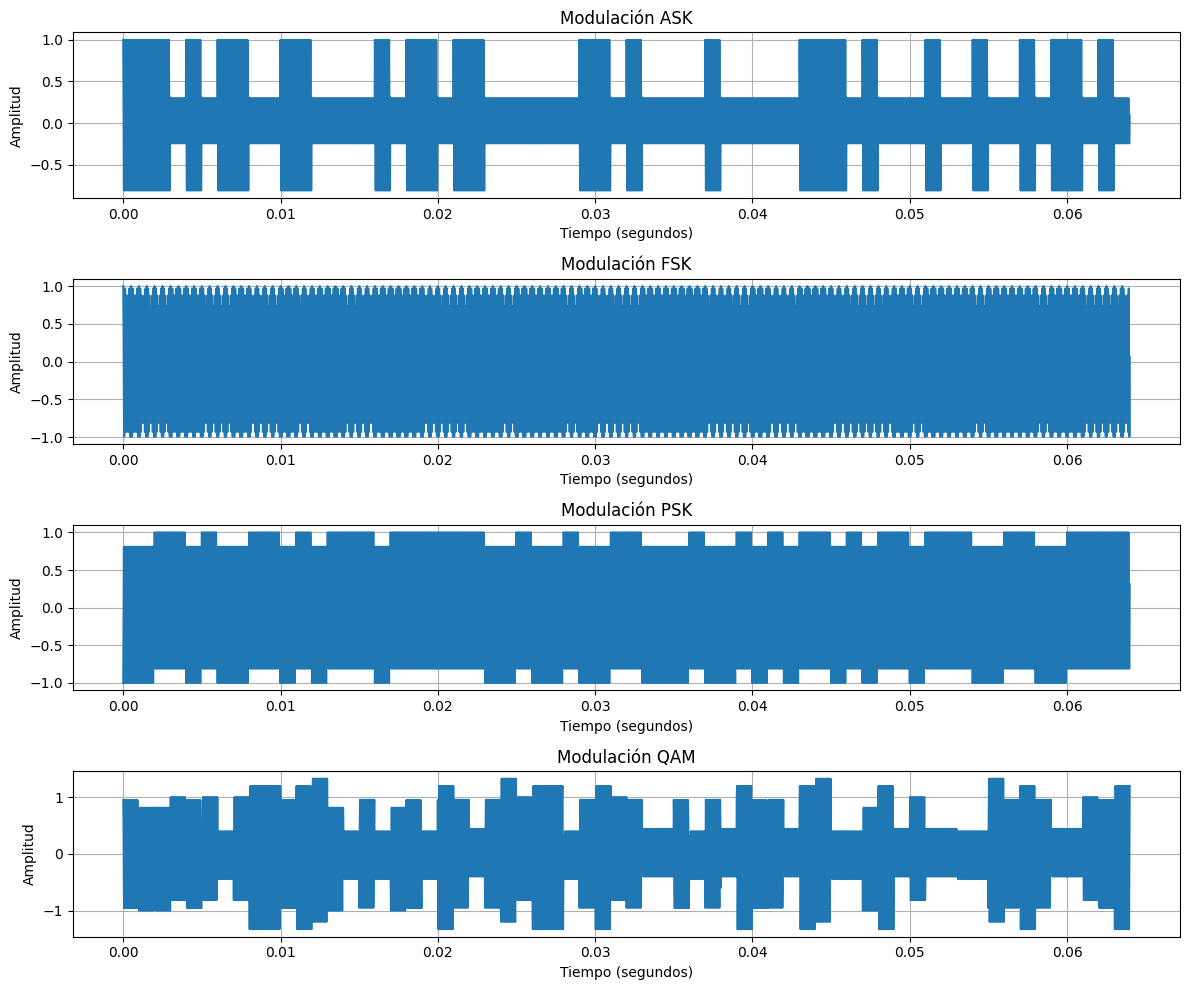

In [ ]:
fig, ejes = plt.subplots(4, 1, figsize=(12, 10))

for i, (nombre, funcion) in enumerate(generadores.items()):

    señal = funcion()

    tiempo = np.arange(len(señal)) / fs

    ejes[i].plot(tiempo, señal)

    ejes[i].set_title("Modulación " + nombre)
    ejes[i].set_xlabel("Tiempo (segundos)")
    ejes[i].set_ylabel("Amplitud")
    ejes[i].grid()

plt.tight_layout()
plt.show()

In [ ]:
np.savez_compressed(
    "dataset_modulaciones.npz",

    X_limpio=X_limpio,
    X_ruidoso=X_ruidoso,
    etiquetas=y,
    snr=snr_final,

    X_train=X_train,
    X_test=X_test,

    y_train=y_train,
    y_test=y_test
)

print("Dataset guardado correctamente")

Dataset guardado correctamente


In [ ]:
from google.colab import files

files.download("dataset_modulaciones.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# FASE 2 - 2.2 DISEÑO DEL MODELO
# Cargar los datos generados en la Fase 1

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

from google.colab import files
import os

# Verificar que exista el archivo de la Fase 1
if not os.path.exists("dataset_modulaciones.npz"):
    print("Sube el archivo dataset_modulaciones.npz")
    uploaded = files.upload()

# Cargar dataset
datos = np.load("dataset_modulaciones.npz", allow_pickle=True)

print("Contenido del archivo:")
print(datos.files)

# Recuperar señales con ruido y sus etiquetas
X = datos["X_ruidoso"]
y = datos["etiquetas"]

print("\nDimensiones de los datos:")
print("Señales:", X.shape)
print("Etiquetas:", y.shape)

print("\nModulaciones disponibles:")
print(np.unique(y))


Sube el archivo dataset_modulaciones.npz


Saving dataset_modulaciones.npz to dataset_modulaciones.npz
Contenido del archivo:
['X_limpio', 'X_ruidoso', 'etiquetas', 'snr', 'X_train', 'X_test', 'y_train', 'y_test']

Dimensiones de los datos:
Señales: (4000, 3200)
Etiquetas: (4000,)

Modulaciones disponibles:
['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:

# PASO 2: PREPARAR LOS DATOS PARA LA CNN

# Convertir señales a formato float32
X = X.astype("float32")

# Codificar las etiquetas
codificador = LabelEncoder()
y_codificado = codificador.fit_transform(y)

# Convertir etiquetas a formato One-Hot
y_categorico = to_categorical(y_codificado, num_classes=4)

# Agregar dimensión de canal
X = X.reshape(X.shape[0], X.shape[1], 1)

# Separar entrenamiento y prueba (80% y 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorico,
    test_size=0.20,
    random_state=42,
    stratify=y_codificado
)

print("PREPARACION TERMINADA")
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Clases:", codificador.classes_)


PREPARACION TERMINADA
Entrenamiento: (3200, 3200, 1)
Prueba: (800, 3200, 1)
Clases: ['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:

# PASO 3: CONSTRUCCION DEL MODELO CNN

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense

modelo = Sequential([

    # Entrada de las señales
    tf.keras.layers.Input(shape=(3200, 1)),

    # Primera capa convolucional
    Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu"
    ),

    # Segunda capa convolucional
    Conv1D(
        filters=64,
        kernel_size=5,
        activation="relu"
    ),

    # Aplanar los datos
    Flatten(),

    # Clasificar las cuatro modulaciones
    Dense(4, activation="softmax")
])

# Mostrar la estructura de la red neuronal
modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3196, 32)       │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 3192, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 204288)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       817,156 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 827,652 (3.16 MB)

 Trainable params: 827,652 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# PASO 4: COMPILAR EL MODELO

modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MODELO COMPILADO CORRECTAMENTE")


MODELO COMPILADO CORRECTAMENTE


In [ ]:

# PASO 5: ENTRENAR LA RED NEURONAL

print("INICIANDO ENTRENAMIENTO...")

historial = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

print("ENTRENAMIENTO FINALIZADO")


INICIANDO ENTRENAMIENTO...
Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 261ms/step - accuracy: 0.9578 - loss: 0.1894 - val_accuracy: 1.0000 - val_loss: 4.1768e-04
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 41s 265ms/step - accuracy: 1.0000 - loss: 2.7429e-05 - val_accuracy: 1.0000 - val_loss: 2.0244e-04
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 40s 256ms/step - accuracy: 1.0000 - loss: 1.4821e-05 - val_accuracy: 1.0000 - val_loss: 1.4057e-04
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 40s 245ms/step - accuracy: 1.0000 - loss: 1.1097e-05 - val_accuracy: 1.0000 - val_loss: 1.0288e-04
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 237ms/step - accuracy: 1.0000 - loss: 8.9023e-06 - val_accuracy: 1.0000 - val_loss: 8.4827e-05
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 258ms/step - accuracy: 1.0000 - loss: 7.4616e-06 - val_accuracy: 1.0000 - val_loss: 7.1185e-05
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 40s 250ms/step - accuracy: 1.0000 - loss: 6.3578e-06 - val_accuracy: 1.0000 - val_loss: 6.2335e-05
Epoch 8/20
80/80 ━

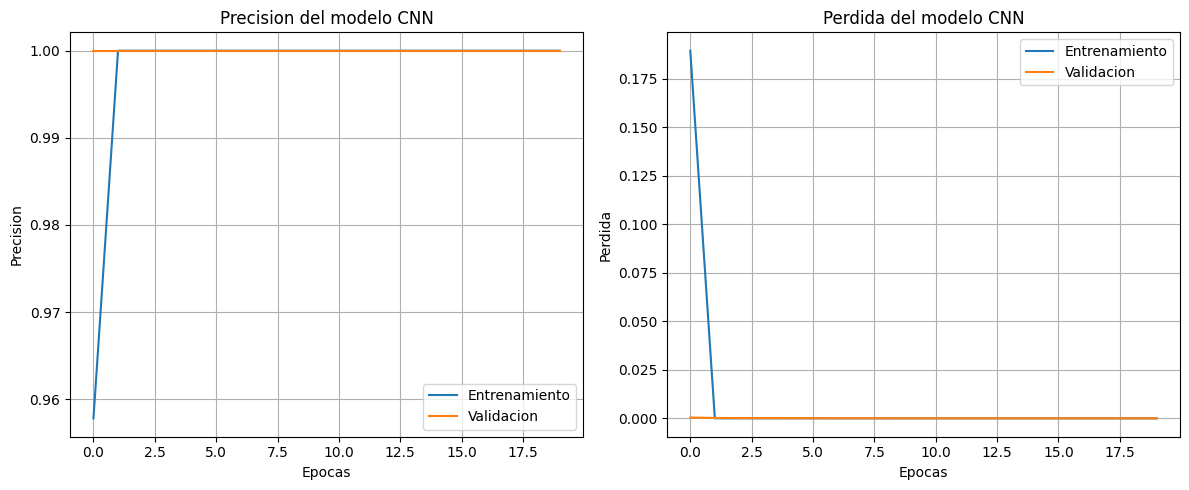

In [ ]:

# PASO 6: GRAFICAS DEL ENTRENAMIENTO

plt.figure(figsize=(12, 5))

# Grafica de precision
plt.subplot(1, 2, 1)

plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validacion")

plt.title("Precision del modelo CNN")
plt.xlabel("Epocas")
plt.ylabel("Precision")
plt.legend()
plt.grid()

# Grafica de perdida
plt.subplot(1, 2, 2)

plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validacion")

plt.title("Perdida del modelo CNN")
plt.xlabel("Epocas")
plt.ylabel("Perdida")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


In [ ]:

# PASO 7: EVALUACION DEL MODELO

perdida, precision = modelo.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nRESULTADOS DE EVALUACION")
print("Perdida:", perdida)
print("Precision:", precision * 100, "%")


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 1.0000 - loss: 1.3981e-05

RESULTADOS DE EVALUACION
Perdida: 1.3981250958750024e-05
Precision: 100.0 %


In [ ]:

# PASO 8: GUARDAR EL MODELO ENTRENADO

# Guardar la red neuronal
modelo.save("modelo_detector_senales.keras")

# Guardar las clases
np.save("clases_modulacion.npy", codificador.classes_)

print("MODELO GUARDADO CORRECTAMENTE")
print("Archivo: modelo_detector_senales.keras")
print("Clases: clases_modulacion.npy")


MODELO GUARDADO CORRECTAMENTE
Archivo: modelo_detector_senales.keras
Clases: clases_modulacion.npy


In [ ]:

# DESCARGAR LOS ARCHIVOS

from google.colab import files

files.download("modelo_detector_senales.keras")
files.download("clases_modulacion.npy")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#fase 3

# PASO 1: CARGAR EL MODELO ENTRENADO

from tensorflow.keras.models import load_model
import numpy as np

# Cargar el modelo
modelo = load_model("modelo_detector_senales.keras")

# Cargar las clases
clases = np.load("clases_modulacion.npy")

print("MODELO CARGADO CORRECTAMENTE")
print("Clases de modulación:", clases)

ValueError: File not found: filepath=modelo_detector_senales.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:

# PASO 1: SUBIR LOS ARCHIVOS DEL MODELO

from google.colab import files

archivos = files.upload()


Saving modelo_detector_senales.keras to modelo_detector_senales.keras
Saving clases_modulacion.npy to clases_modulacion.npy


In [ ]:

# PASO 2: CARGAR EL MODELO ENTRENADO

from tensorflow.keras.models import load_model
import numpy as np

# Cargar modelo
modelo = load_model("modelo_detector_senales.keras")

# Cargar clases
clases = np.load("clases_modulacion.npy")

print("MODELO CARGADO CORRECTAMENTE")
print("Clases de modulación:", clases)


MODELO CARGADO CORRECTAMENTE
Clases de modulación: ['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:

# PASO 3: PREPARAR LOS DATOS DE PRUEBA

from sklearn.model_selection import train_test_split

# Recuperar los datos originales
datos = np.load("dataset_modulaciones.npz")

X = datos["X"]
y = datos["y"]

# Dividir los datos con la misma configuración de la Fase 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATOS DE PRUEBA PREPARADOS")
print("Total de señales:", len(X))
print("Señales para prueba:", len(X_test))
print("Forma de X_test:", X_test.shape)
print("Forma de y_test:", y_test.shape)


FileNotFoundError: [Errno 2] No such file or directory: 'dataset_modulaciones.npz'

In [ ]:

# PASO 3: SUBIR EL DATASET ORIGINAL

from google.colab import files

archivos = files.upload()


Saving dataset_modulaciones.npz to dataset_modulaciones.npz


In [ ]:

import numpy as np

datos = np.load("dataset_modulaciones.npz")

print("DATASET CARGADO CORRECTAMENTE")
print("Archivos disponibles:", datos.files)


DATASET CARGADO CORRECTAMENTE
Archivos disponibles: ['X_limpio', 'X_ruidoso', 'etiquetas', 'snr', 'X_train', 'X_test', 'y_train', 'y_test']


In [ ]:

# PASO 4: REALIZAR LAS PREDICCIONES

# Obtener los datos de prueba originales
X_test = datos["X_test"]
y_test = datos["y_test"]

# Realizar predicciones con el modelo CNN
predicciones = modelo.predict(X_test)

# Convertir las predicciones a clases
y_pred = np.argmax(predicciones, axis=1)

# Convertir las etiquetas reales a clases
if len(y_test.shape) > 1 and y_test.shape[-1] > 1:
    y_real = np.argmax(y_test, axis=1)
else:
    y_real = y_test.flatten().astype(int)

print("PREDICCIONES REALIZADAS CORRECTAMENTE")
print("Total de señales evaluadas:", len(X_test))
print("Predicciones:", len(y_pred))
print("Etiquetas reales:", len(y_real))


In [ ]:

# PASO 5: GENERAR LA MATRIZ DE CONFUSIÓN

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Crear matriz de confusión
matriz = confusion_matrix(
    y_real,
    y_pred,
    labels=np.arange(len(clases))
)

# Mostrar resultados
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases
)

plt.title("Matriz de Confusión - Detector de Señales CNN")
plt.xlabel("Modulación Predicha")
plt.ylabel("Modulación Real")
plt.tight_layout()
plt.show()

# Reporte de clasificación
print("REPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_real,
    y_pred,
    labels=np.arange(len(clases)),
    target_names=clases
))


In [ ]:

# PASO 4: CORREGIR Y PREPARAR LAS PREDICCIONES

import numpy as np

# Obtener las etiquetas reales
y_test = datos["y_test"]

# Convertir las etiquetas de texto a números
y_real = np.array([
    np.where(clases == etiqueta)[0][0]
    for etiqueta in y_test.flatten()
])

# Convertir las predicciones del modelo
y_pred = np.argmax(predicciones, axis=1)

print("PREDICCIONES PREPARADAS CORRECTAMENTE")
print("Total de señales:", len(y_real))
print("Etiquetas reales:", y_real[:10])
print("Predicciones:", y_pred[:10])


PREDICCIONES PREPARADAS CORRECTAMENTE
Total de señales: 800
Etiquetas reales: [0 1 0 1 0 3 2 2 1 0]
Predicciones: [0 1 0 1 0 3 2 2 1 0]


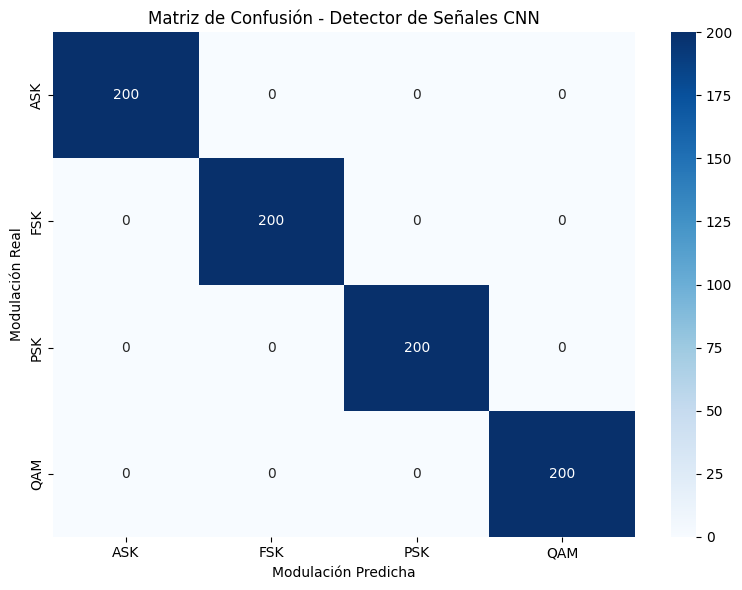

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

         ASK       1.00      1.00      1.00       200
         FSK       1.00      1.00      1.00       200
         PSK       1.00      1.00      1.00       200
         QAM       1.00      1.00      1.00       200

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800



In [ ]:

# PASO 5: MATRIZ DE CONFUSIÓN

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

matriz = confusion_matrix(
    y_real,
    y_pred,
    labels=np.arange(len(clases))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases
)

plt.title("Matriz de Confusión - Detector de Señales CNN")
plt.xlabel("Modulación Predicha")
plt.ylabel("Modulación Real")

plt.tight_layout()
plt.show()

print("REPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_real,
    y_pred,
    labels=np.arange(len(clases)),
    target_names=clases
))


In [ ]:

# FASE 3 - PASO 6: REVISAR DATOS DE RUIDO

X_ruidoso = datos["X_ruidoso"]
etiquetas = datos["etiquetas"]
snr = datos["snr"]

print("DATOS DE RUIDO CARGADOS")
print("Forma de X_ruidoso:", X_ruidoso.shape)
print("Forma de etiquetas:", etiquetas.shape)
print("Forma de SNR:", snr.shape)

print("\nNiveles de SNR disponibles:")
print(np.unique(snr))

print("\nClases disponibles:")
print(np.unique(etiquetas))


DATOS DE RUIDO CARGADOS
Forma de X_ruidoso: (4000, 3200)
Forma de etiquetas: (4000,)
Forma de SNR: (4000,)

Niveles de SNR disponibles:
[ 0  5 10 15 20]

Clases disponibles:
['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:

# PASO 7: ANALIZAR LOS NIVELES DE RUIDO

print("FORMA DE ENTRADA DEL MODELO:")
print(modelo.input_shape)

print("\nDISTRIBUCION DE SEÑALES POR NIVEL SNR:")

for nivel in np.unique(snr):
    cantidad = np.sum(snr == nivel)
    print("SNR", nivel, ":", cantidad, "señales")

print("\nDISTRIBUCION POR MODULACION:")

for clase in clases:
    cantidad = np.sum(etiquetas == clase)
    print(clase, ":", cantidad, "señales")


FORMA DE ENTRADA DEL MODELO:
(None, 3200, 1)

DISTRIBUCION DE SEÑALES POR NIVEL SNR:
SNR 0 : 780 señales
SNR 5 : 785 señales
SNR 10 : 777 señales
SNR 15 : 827 señales
SNR 20 : 831 señales

DISTRIBUCION POR MODULACION:
ASK : 1000 señales
FSK : 1000 señales
PSK : 1000 señales
QAM : 1000 señales


In [ ]:

# PASO 8: PRUEBA DE ESTRES CON RUIDO

from sklearn.metrics import accuracy_score

# Adaptar las señales al formato de entrada de la CNN
X_ruidoso_modelo = X_ruidoso.reshape(4000, 3200, 1)

# Realizar predicciones
predicciones_ruido = modelo.predict(X_ruidoso_modelo)

# Obtener las clases predichas
y_pred_ruido = np.argmax(predicciones_ruido, axis=1)

# Convertir las etiquetas reales a números
y_real_ruido = np.array([
    np.where(clases == etiqueta)[0][0]
    for etiqueta in etiquetas
])

# Calcular precisión por cada nivel de SNR
resultados_snr = {}

print("RESULTADOS DE LA PRUEBA DE ESTRES")
print("----------------------------------")

for nivel in np.unique(snr):

    indices = np.where(snr == nivel)[0]

    precision = accuracy_score(
        y_real_ruido[indices],
        y_pred_ruido[indices]
    )

    resultados_snr[nivel] = precision * 100

    print(f"SNR {nivel}: {precision * 100:.2f}%")

print("----------------------------------")
print("EVALUACION FINALIZADA")


ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:

# PASO 8: VERIFICAR Y PREPARAR LAS SEÑALES

import numpy as np

# Recuperar nuevamente los datos originales
X_ruidoso = np.asarray(datos["X_ruidoso"], dtype=np.float32)

# Comprobar dimensiones
print("Forma original:", X_ruidoso.shape)
print("Tipo de datos:", X_ruidoso.dtype)

# Preparar las señales para la CNN
X_ruidoso_modelo = X_ruidoso.reshape(-1, 3200, 1)

# Comprobar dimensiones finales
print("Forma preparada:", X_ruidoso_modelo.shape)
print("Forma esperada por el modelo:", modelo.input_shape)

print("DATOS PREPARADOS CORRECTAMENTE")


Forma original: (4000, 3200)
Tipo de datos: float32
Forma preparada: (4000, 3200, 1)
Forma esperada por el modelo: (None, 3200, 1)
DATOS PREPARADOS CORRECTAMENTE


In [ ]:

# PASO 9: PREDICCIONES CON DIFERENTES NIVELES DE RUIDO

# Realizar predicciones por lotes
predicciones_ruido = modelo.predict(
    X_ruidoso_modelo,
    batch_size=32,
    verbose=1
)

# Obtener las clases predichas
y_pred_ruido = np.argmax(predicciones_ruido, axis=1)

# Convertir etiquetas reales a números
y_real_ruido = np.array([
    np.where(clases == etiqueta)[0][0]
    for etiqueta in etiquetas
])

print("PREDICCIONES CON RUIDO COMPLETADAS")
print("Total de señales:", len(y_pred_ruido))
print("Etiquetas reales:", len(y_real_ruido))


ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:

# PASO 9: VERIFICAR LA ENTRADA DEL MODELO

import tensorflow as tf
import numpy as np

# Convertir los datos a tensor
X_revision = tf.convert_to_tensor(
    X_ruidoso_modelo[:32],
    dtype=tf.float32
)

print("FORMA DE LOS DATOS:", X_revision.shape)
print("TIPO DE DATOS:", X_revision.dtype)
print("ENTRADA DEL MODELO:", modelo.input_shape)

# Probar solamente 32 señales
try:
    prueba = modelo(X_revision, training=False)
    print("PRUEBA CORRECTA")
    print("Forma de salida:", prueba.shape)

except Exception as e:
    print("ERROR DETECTADO:", str(e))


FORMA DE LOS DATOS: (32, 3200, 1)
TIPO DE DATOS: <dtype: 'float32'>
ENTRADA DEL MODELO: (None, 3200, 1)
PRUEBA CORRECTA
Forma de salida: (32, 4)


In [ ]:

# PASO 10: EVALUACION DE SEÑALES CON RUIDO

# Realizar predicciones por bloques
lotes = []

for inicio in range(0, len(X_ruidoso_modelo), 32):

    fin = inicio + 32

    bloque = tf.convert_to_tensor(
        X_ruidoso_modelo[inicio:fin],
        dtype=tf.float32
    )

    salida = modelo(bloque, training=False)

    lotes.append(salida.numpy())

# Unir todas las predicciones
predicciones_ruido = np.concatenate(lotes, axis=0)

# Obtener clases predichas
y_pred_ruido = np.argmax(predicciones_ruido, axis=1)

# Convertir etiquetas reales
y_real_ruido = np.array([
    np.where(clases == etiqueta)[0][0]
    for etiqueta in etiquetas
])

print("EVALUACION COMPLETADA")
print("Total de señales:", len(y_pred_ruido))
print("Forma de predicciones:", predicciones_ruido.shape)


EVALUACION COMPLETADA
Total de señales: 4000
Forma de predicciones: (4000, 4)


In [ ]:

# PASO 11: CALCULAR PRECISION POR NIVEL SNR

from sklearn.metrics import accuracy_score

resultados_snr = {}

print("RESULTADOS DE LA PRUEBA DE ESTRES")
print("----------------------------------")

for nivel in np.unique(snr):

    indices = np.where(snr == nivel)[0]

    precision = accuracy_score(
        y_real_ruido[indices],
        y_pred_ruido[indices]
    )

    resultados_snr[nivel] = precision * 100

    print(f"SNR {nivel}: {precision * 100:.2f}%")

print("----------------------------------")
print("EVALUACION FINALIZADA")


RESULTADOS DE LA PRUEBA DE ESTRES
----------------------------------
SNR 0: 100.00%
SNR 5: 100.00%
SNR 10: 100.00%
SNR 15: 100.00%
SNR 20: 100.00%
----------------------------------
EVALUACION FINALIZADA


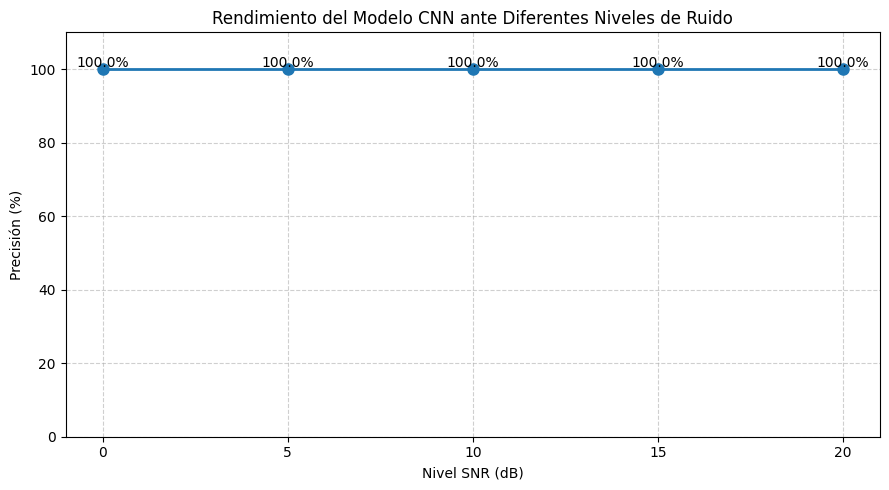

GRAFICA DE RENDIMIENTO GENERADA


In [ ]:

# FASE 3 - PASO 12: GRAFICA DE RENDIMIENTO

import matplotlib.pyplot as plt

# Obtener niveles SNR y precisión
niveles = list(resultados_snr.keys())
precisiones = list(resultados_snr.values())

# Crear gráfica
plt.figure(figsize=(9, 5))

plt.plot(
    niveles,
    precisiones,
    marker='o',
    linewidth=2,
    markersize=8
)

# Agregar valores a cada punto
for x, y in zip(niveles, precisiones):
    plt.text(x, y + 0.5, f'{y:.1f}%', ha='center')

plt.title("Rendimiento del Modelo CNN ante Diferentes Niveles de Ruido")
plt.xlabel("Nivel SNR (dB)")
plt.ylabel("Precisión (%)")

plt.xticks(niveles)
plt.ylim(0, 110)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("GRAFICA DE RENDIMIENTO GENERADA")


In [ ]:

# FASE 3 - PASO 13: ANALISIS DE ERRORES POR MODULACION

from sklearn.metrics import confusion_matrix
import numpy as np

# Crear matriz de confusion con señales ruidosas
matriz_ruido = confusion_matrix(
    y_real_ruido,
    y_pred_ruido,
    labels=np.arange(len(clases))
)

print("ANALISIS DE ERRORES POR MODULACION")
print("----------------------------------")

for i, clase in enumerate(clases):

    total = np.sum(matriz_ruido[i])
    correctas = matriz_ruido[i, i]
    errores = total - correctas

    precision = (correctas / total) * 100

    print("\nModulacion:", clase)
    print("Total de señales:", total)
    print("Clasificadas correctamente:", correctas)
    print("Errores:", errores)
    print("Precision:", f"{precision:.2f}%")

print("\nANALISIS FINALIZADO")


ANALISIS DE ERRORES POR MODULACION
----------------------------------

Modulacion: ASK
Total de señales: 1000
Clasificadas correctamente: 1000
Errores: 0
Precision: 100.00%

Modulacion: FSK
Total de señales: 1000
Clasificadas correctamente: 1000
Errores: 0
Precision: 100.00%

Modulacion: PSK
Total de señales: 1000
Clasificadas correctamente: 1000
Errores: 0
Precision: 100.00%

Modulacion: QAM
Total de señales: 1000
Clasificadas correctamente: 1000
Errores: 0
Precision: 100.00%

ANALISIS FINALIZADO


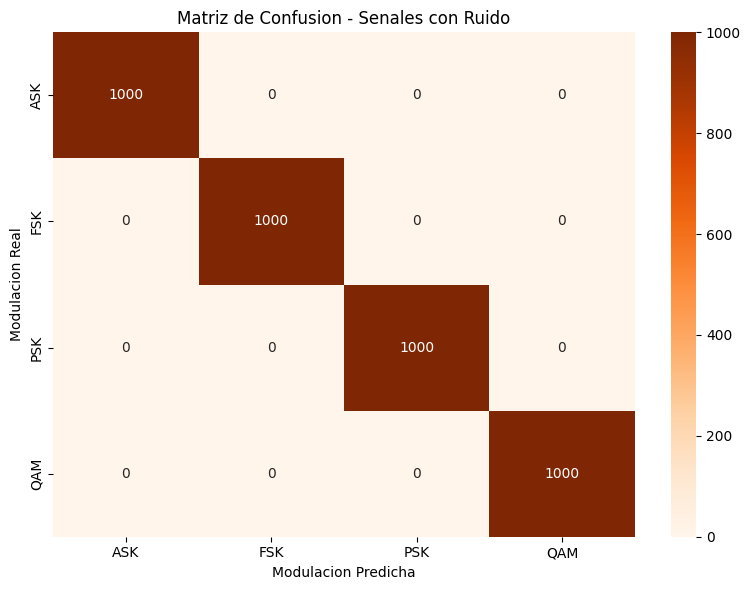

MATRIZ DE CONFUSION CON RUIDO GENERADA


In [ ]:

# PASO 14: MATRIZ DE CONFUSION CON RUIDO

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_ruido,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=clases,
    yticklabels=clases
)

plt.title("Matriz de Confusion - Senales con Ruido")
plt.xlabel("Modulacion Predicha")
plt.ylabel("Modulacion Real")

plt.tight_layout()
plt.show()

print("MATRIZ DE CONFUSION CON RUIDO GENERADA")
